Example 6: Interaction Diagnostics (has Beer-Lambert additivity failed?)

SYNTHETIC DATA. Every spectrum, rate constant, band position, concentration, and
noise sample in this file is generated by the model below. Nothing here is
measured, fitted to experiment, or validated against real data. The numbers are
illustrative and were chosen only to be qualitatively like a real Raman kinetics
run. These scripts demonstrate method behaviour, not physical parameter values.

This example is a DIAGNOSTIC, not an estimation. It runs BEFORE any model
augmentation and answers a single question: has Beer-Lambert additivity failed,
so that a plain ``D = C @ S.T`` model is misspecified and an interaction term is
warranted? Two pieces of evidence answer it.

The first is rank. Beer-Lambert bilinearity says the data matrix factors as
``D(t, nu) = sum_k c_k(t) s_k(nu)``, one fixed pure spectrum per absorbing
species, contributions simply adding. A direct consequence is that the numerical
rank of D equals the number of species. Three additive species therefore produce
three singular values above the noise floor. When A and B associate into a
transient adduct, the pair gains a vibrational mode neither monomer has whose
intensity tracks the product ``c_A * c_B``, a bilinear-in-concentration virial
correction. When the environment shifts a band center as composition changes,
that shift is, to first order, a new additive derivative band. Each mechanism
adds a column that no single concentration profile can represent, so the
effective rank climbs above the species count, here from three to about five. Any
method that assumes ``rank(D) = n_species`` is now solving the wrong problem.

The second is the residual. Project the interacting data onto the three true
concentration profiles and read off the best additive spectra by least squares,
exactly the inner spectra-resolution step MCR and KIPET perform. On additive data
the leftover is white measurement noise. On interacting data the leftover is
STRUCTURED: vertical bands of residual sit directly under the adduct mode near
1150 cm^-1 and under the shifting mode near 1600 cm^-1, because a rank-3 additive
model cannot reach into those columns no matter how the spectra are chosen. A
residual that concentrates at specific wavenumbers, rather than spreading like
noise, is the fingerprint that additivity broke.

To generate the concentrations honestly the script does not hand-roll an ODE
integrator. It builds a kipetax ReactionModel for A -> B -> C, calls
``r.simulate()``, and reads the collocated trajectory from
``r.results_dict['simulator'].Z``. Those profiles feed the synthetic Raman
matrices, and the SVD and residual diagnostics are done in NumPy on the resulting
D matrices.

The punchline: model selection precedes model augmentation. The rank-inflation and
structured-residual checks shown here are the evidence a user should have in hand
BEFORE reaching for ``r.interaction()``. Example 4
(``Ex_4_spectral_interactions.py``) picks up exactly where this leaves off: it
takes the same A -> B -> C chemistry and the same ``c_A * c_B`` adduct band and
shows that declaring ``r.interaction('AB', A * B)`` removes the bias an additive
fit would otherwise bake into the rate constants. Run this first to decide whether
that augmentation is justified; run Example 4 to carry it out.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import os

## Setup: helper functions and synthetic-data generators

These are lifted verbatim from the example script (`kipetax/examples/Ex_6_interaction_diagnostics.py`).

In [2]:
import numpy as np

from kipetax import ReactionModel

# ── True kinetics and interaction strengths (data generation only) ──
K1_TRUE, K2_TRUE = 0.9, 0.5
A0 = 1.0
G_STRENGTH = 1.6      # adduct band strength (virial c_A*c_B term)
DELTA = 12.0          # cm^-1 of band shift per unit concentration

# ── Measurement grids ──
NU = np.linspace(200.0, 1800.0, 400)      # Raman shift / wavenumber (cm^-1)
T = np.linspace(0.0, 10.0, 60)            # measurement times

# ── Band shapes. Raman bands are well described by Lorentzians. ──
# These four definitions and the DELTA shift are copied verbatim from the
# standalone raman_interactions.py demo so the diagnostic matches it exactly.
def lorentzian(nu, nu0, gamma, amp):
    """A Lorentzian band.

    Parameters
    ----------
    nu : array_like
        Wavenumber axis (cm^-1).
    nu0 : float
        Band center (cm^-1).
    gamma : float
        Half-width at half-maximum (cm^-1).
    amp : float
        Peak amplitude.

    Returns
    -------
    ndarray
        Band intensity at each ``nu``.
    """
    return amp * gamma ** 2 / ((nu - nu0) ** 2 + gamma ** 2)

def spec_A(nu):
    """Pure spectrum of species A."""
    return lorentzian(nu, 520.0, 15.0, 1.0) + lorentzian(nu, 1000.0, 20.0, 0.6)

def spec_B(nu):
    """Pure spectrum of species B."""
    return lorentzian(nu, 700.0, 18.0, 0.8) + lorentzian(nu, 1350.0, 25.0, 0.7)

def spec_C_band(nu, shift):
    """Spectrum of product C. Its 1600 cm^-1 mode shifts with environment.

    Parameters
    ----------
    nu : array_like
        Wavenumber axis (cm^-1).
    shift : float or array_like
        Displacement of the 1600 cm^-1 band center (cm^-1). Broadcasts against
        ``nu`` so a per-time column of shifts yields a stack of spectra.

    Returns
    -------
    ndarray
        Band intensity.
    """
    return lorentzian(nu, 900.0, 20.0, 0.9) + lorentzian(nu, 1600.0 + shift, 22.0, 1.0)

def spec_C(nu):
    """Unshifted spectrum of product C."""
    return spec_C_band(nu, 0.0)

def spec_complex_AB(nu):
    """Vibrational mode unique to the A.B adduct; exists only when both present."""
    return lorentzian(nu, 1150.0, 20.0, 0.7)

def simulate_concentrations():
    """Generate the A -> B -> C concentration profiles with kipetax.

    Builds a ReactionModel with the consecutive first-order ODEs, runs a pure
    simulation, and interpolates the collocated trajectory onto the measurement
    times ``T``. The rate constants are chosen so the three profiles are linearly
    independent, which is what gives the additive data genuine rank three.

    Returns
    -------
    cA, cB, cC : ndarray
        Concentration of each species at every time in ``T``.
    """
    r = ReactionModel('Ex_6_ABC')

    # Parameters are fixed: this is a forward simulation, not an estimation.
    k1 = r.parameter('k1', value=K1_TRUE, bounds=(0, 10), fixed=True)
    k2 = r.parameter('k2', value=K2_TRUE, bounds=(0, 5), fixed=True)

    A = r.component('A', value=A0)
    B = r.component('B', value=0.0)
    C = r.component('C', value=0.0)

    r.add_ode('A', -k1 * A)
    r.add_ode('B', k1 * A - k2 * B)
    r.add_ode('C', k2 * B)

    # simulate() requires a time span and now RAISES RuntimeError if the
    # collocation solve fails, so no silent empty trajectory can slip through.
    r.set_time(10.0)
    r.set_discretization(nfe=50, ncp=3)
    r.simulate()

    # Z is indexed at the collocation points, NOT at the measurement times, so
    # interpolate each column onto T before building the spectra.
    Z = r.results_dict['simulator'].Z
    cA = np.interp(T, Z.index.values, Z['A'].values)
    cB = np.interp(T, Z.index.values, Z['B'].values)
    cC = np.interp(T, Z.index.values, Z['C'].values)
    return cA, cB, cC

def build_data(cA, cB, cC, noise=2e-3, seed=0):
    """Assemble the additive and interacting synthetic Raman matrices.

    Parameters
    ----------
    cA, cB, cC : ndarray
        Concentration profiles from :func:`simulate_concentrations`.
    noise : float
        Standard deviation of additive white measurement noise.
    seed : int
        Seed for the noise generator.

    Returns
    -------
    dict
        ``D_add`` (bilinear ground truth), ``D_int`` (with both interactions),
        the pure spectra, and the two interaction contributions.
    """
    SA, SB, SC = spec_A(NU), spec_B(NU), spec_C(NU)

    # (0) additive / bilinear ground truth: D = C @ S.T
    D_add = np.outer(cA, SA) + np.outer(cB, SB) + np.outer(cC, SC)

    # (1) adduct band: intensity proportional to c_A * c_B (a virial term).
    interaction_complex = G_STRENGTH * np.outer(cA * cB, spec_complex_AB(NU))

    # (2) environment-dependent shift of C's 1600 band: nu0 -> nu0 + DELTA*c_C.
    # The per-time shifted spectrum, scaled by c_C, minus the unshifted
    # contribution, is what a rank-3 additive model cannot represent.
    shifts = DELTA * cC
    SC_shifted = spec_C_band(NU[None, :], shifts[:, None])   # (nt, n_nu)
    contrib_C_shifted = cC[:, None] * SC_shifted
    contrib_C_unshifted = np.outer(cC, SC)
    interaction_shift = contrib_C_shifted - contrib_C_unshifted

    D_int = D_add + interaction_complex + interaction_shift

    rng = np.random.default_rng(seed)
    D_add = D_add + noise * rng.standard_normal(D_add.shape)
    D_int = D_int + noise * rng.standard_normal(D_int.shape)

    return dict(
        D_add=D_add, D_int=D_int, SA=SA, SB=SB, SC=SC,
        interaction_complex=interaction_complex,
        interaction_shift=interaction_shift,
    )

def bilinear_residual(D, C):
    """Best additive fit ``D ~ C @ S.T`` for a GIVEN concentration matrix C.

    This is the inner spectra-resolution step MCR and KIPET perform. With C
    known from the kinetics, the pure spectra follow from least squares and the
    residual measures how non-additive the data is.

    Parameters
    ----------
    D : ndarray
        Data matrix (n_times x n_wavenumbers).
    C : ndarray
        Concentration matrix (n_times x n_components).

    Returns
    -------
    S, D_hat, R : ndarray
        Resolved spectra, reconstruction, and residual ``D - D_hat``.
    """
    S = np.linalg.pinv(C) @ D
    D_hat = C @ S
    return S, D_hat, D - D_hat

def rmse(x):
    """Root-mean-square of an array."""
    return float(np.sqrt(np.mean(np.asarray(x) ** 2)))

def shift_is_derivative_band():
    """Show that a peak shift is, to first order, an additive derivative band.

    A band displaced by ``delta`` obeys ``s(nu - delta) ~= s(nu) - delta*s'(nu)``,
    so a small shift masquerades as a new additive spectrum shaped like the
    derivative of a real one. The derivative comes straight from ``jax.grad``.
    This is why the concentration-dependent shift inflates the rank: it injects a
    derivative-shaped column. Reported briefly for a few shift sizes.
    """
    import jax
    from jax import grad, vmap

    jax.config.update("jax_enable_x64", True)
    NU_j = np.asarray(NU)

    # d/d(shift) of C's spectrum at zero shift, per wavenumber.
    dS_dshift = vmap(lambda nu: grad(lambda sh: spec_C_band(nu, sh))(0.0))(NU_j)
    dS_dshift = np.asarray(dS_dshift)
    unshifted = spec_C_band(NU, 0.0)

    rows = []
    for delta in (1.0, 3.0, 6.0, 12.0):
        exact = spec_C_band(NU, delta) - unshifted
        first_order = delta * dS_dshift
        rel = rmse(exact - first_order) / rmse(exact)
        rows.append((delta, rel))
    return rows

def _optional_figure(sv_add, sv_int, R_int, col_rmse_int):
    """Draw the SVD, the structured residual, and its per-wavenumber profile.

    Optional and guarded: the printed diagnostics are the deliverable. A missing
    matplotlib simply skips the figure.
    """
    try:
        import matplotlib
        import matplotlib.pyplot as plt
    except ImportError:
        print("\n(matplotlib not installed, skipping figure)")
        return

    fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))

    n = min(10, len(sv_add))
    ax[0].semilogy(range(1, n + 1), sv_add[:n], "o-", label="additive")
    ax[0].semilogy(range(1, n + 1), sv_int[:n], "s-", label="interacting")
    ax[0].axvline(3.5, color="k", ls=":", lw=1)
    ax[0].set(title="Rank inflation (SVD)", xlabel="component",
              ylabel="singular value")
    ax[0].legend()

    im = ax[1].imshow(R_int, aspect="auto", cmap="RdBu",
                      extent=[NU[0], NU[-1], T[-1], T[0]])
    ax[1].set(title="Naive 3-species residual\n(structured = model wrong)",
              xlabel="cm$^{-1}$", ylabel="time")
    fig.colorbar(im, ax=ax[1], fraction=0.046)

    ax[2].plot(NU, col_rmse_int)
    ax[2].axvline(1150, color="k", ls=":", lw=1)
    ax[2].axvline(1600, color="k", ls="--", lw=1)
    ax[2].set(title="Per-wavenumber residual RMSE",
              xlabel="cm$^{-1}$", ylabel="residual RMSE")

    fig.tight_layout()

## Run the analysis

In [3]:
cA, cB, cC = simulate_concentrations()
d = build_data(cA, cB, cC)
D_add, D_int = d['D_add'], d['D_int']

Simulation complete: status=optimal


In [4]:
# The naive model: exactly the three true species, no interaction column.
C3 = np.stack([cA, cB, cC], axis=1)

In [5]:
# ── 1. rank inflation via SVD ──
sv_add = np.linalg.svd(D_add, compute_uv=False)
sv_int = np.linalg.svd(D_int, compute_uv=False)

In [6]:
# ── 2. naive 3-species bilinear fit and its residual ──
_, _, R_add = bilinear_residual(D_add, C3)
_, _, R_int = bilinear_residual(D_int, C3)

In [7]:
# Structure of the interacting residual: per-wavenumber RMSE. Additivity
# failure shows up as sharp peaks (vertical residual bands), not a flat
# noise profile.
col_rmse_add = np.sqrt(np.mean(R_add ** 2, axis=0))
col_rmse_int = np.sqrt(np.mean(R_int ** 2, axis=0))
struct_ratio_add = float(col_rmse_add.max() / np.median(col_rmse_add))
struct_ratio_int = float(col_rmse_int.max() / np.median(col_rmse_int))
med_int = float(np.median(col_rmse_int))
# The residual should spike in BOTH the adduct region (near 1150) and the
# shift region (near 1600). Report each region's peak so both bands show.
lo, hi = NU < 1400.0, NU >= 1400.0
nu_adduct = float(NU[lo][np.argmax(col_rmse_int[lo])])
peak_adduct = float(col_rmse_int[lo].max())
nu_shift = float(NU[hi][np.argmax(col_rmse_int[hi])])
peak_shift = float(col_rmse_int[hi].max())

In [8]:
print("=" * 70)
print("INTERACTION DIAGNOSTICS  --  has Beer-Lambert additivity failed?")
print("(SYNTHETIC, illustrative data -- not experimental measurements.)")
print("=" * 70)
print(f"\nData size: {D_int.shape[0]} times x {D_int.shape[1]} wavenumbers")
print(f"True chemical species: 3 (A, B, C), concentrations from r.simulate()")

INTERACTION DIAGNOSTICS  --  has Beer-Lambert additivity failed?
(SYNTHETIC, illustrative data -- not experimental measurements.)

Data size: 60 times x 400 wavenumbers
True chemical species: 3 (A, B, C), concentrations from r.simulate()


In [9]:
print("\n[1] Singular values -- effective rank of D")
print("     idx   additive       interacting")
for i in range(7):
    print(f"     {i:2d}   {sv_add[i]:11.5f}   {sv_int[i]:11.5f}")
print("     -> additive data: 3 components dominate (= n_species), then a")
print("        sharp drop to the noise floor.")
print("     -> interacting data: about 5 components stand above the floor.")
print("        The adduct band and the band shift each add one. Any method")
print("        assuming rank(D) = n_species is now misspecified.")


[1] Singular values -- effective rank of D
     idx   additive       interacting
      0      23.12421      23.10848
      1       6.85823       7.13519
      2       3.43282       3.49845
      3       0.05301       0.77542
      4       0.05279       0.12720
      5       0.05131       0.05475
      6       0.05079       0.05207
     -> additive data: 3 components dominate (= n_species), then a
        sharp drop to the noise floor.
     -> interacting data: about 5 components stand above the floor.
        The adduct band and the band shift each add one. Any method
        assuming rank(D) = n_species is now misspecified.


In [10]:
print("\n[2] Naive 3-species bilinear fit  D ~ C @ S.T  (C = true A,B,C)")
print(f"     residual RMSE, additive data    : {rmse(R_add):.3e}  (~noise)")
print(f"     residual RMSE, interacting data : {rmse(R_int):.3e}  (inflated)")
print(f"     structure ratio (max/median per-wavenumber RMSE):")
print(f"        additive data    : {struct_ratio_add:6.2f}  (flat = white noise)")
print(f"        interacting data : {struct_ratio_int:6.2f}  (peaked = structured)")
print(f"     interacting residual spikes in two places (median = {med_int:.2e}):")
print(f"        {nu_adduct:6.0f} cm^-1  RMSE {peak_adduct:.2e}  (adduct band, ~1150)")
print(f"        {nu_shift:6.0f} cm^-1  RMSE {peak_shift:.2e}  (shifting mode, ~1600)")
print("     -> vertical residual bands under both interaction modes; a")
print("        structured residual is the fingerprint that additivity broke.")


[2] Naive 3-species bilinear fit  D ~ C @ S.T  (C = true A,B,C)
     residual RMSE, additive data    : 1.938e-03  (~noise)
     residual RMSE, interacting data : 5.535e-03  (inflated)
     structure ratio (max/median per-wavenumber RMSE):
        additive data    :   1.35  (flat = white noise)
        interacting data :  16.69  (peaked = structured)
     interacting residual spikes in two places (median = 2.04e-03):
          1150 cm^-1  RMSE 3.40e-02  (adduct band, ~1150)
          1599 cm^-1  RMSE 1.41e-02  (shifting mode, ~1600)
     -> vertical residual bands under both interaction modes; a
        structured residual is the fingerprint that additivity broke.


In [11]:
print("\n[3] Why the shift inflates the rank: a peak shift is a hidden")
print("    additive band equal to the DERIVATIVE of a real one (jax.grad).")
print("     shift(cm^-1)   rel. error of s(nu-delta) ~= s(nu) - delta*s'(nu)")
for delta, rel in shift_is_derivative_band():
    print(f"       {delta:5.0f}          {rel:7.2%}")
print("     -> a small shift is, to first order, a new additive derivative")
print("        band; the linear approximation degrades as the shift grows.")


[3] Why the shift inflates the rank: a peak shift is a hidden
    additive band equal to the DERIVATIVE of a real one (jax.grad).
     shift(cm^-1)   rel. error of s(nu-delta) ~= s(nu) - delta*s'(nu)
           1            3.94%
           3           11.79%
           6           23.47%
          12           46.14%
     -> a small shift is, to first order, a new additive derivative
        band; the linear approximation degrades as the shift grows.


In [12]:
print("\n" + "=" * 70)
print("Verdict: rank climbed 3 -> ~5 and the naive residual is structured.")
print("Additivity has failed. Model selection precedes model augmentation:")
print("this is the evidence to have BEFORE calling r.interaction(). See")
print("Ex_4_spectral_interactions.py, which carries out that augmentation.")
print("=" * 70)


Verdict: rank climbed 3 -> ~5 and the naive residual is structured.
Additivity has failed. Model selection precedes model augmentation:
this is the evidence to have BEFORE calling r.interaction(). See
Ex_4_spectral_interactions.py, which carries out that augmentation.


{'sv_add': array([23.12420769,  6.85822557,  3.43282411,  0.05300677,  0.05278563,
         0.05130972,  0.05079415,  0.05058991,  0.04993817,  0.04967258,
         0.04844958,  0.04764058,  0.04711996,  0.04655005,  0.04606167,
         0.04568394,  0.04521847,  0.04514316,  0.04449794,  0.04385741,
         0.04365612,  0.04274822,  0.04258648,  0.04245902,  0.04175765,
         0.04092771,  0.04057161,  0.04010249,  0.03973474,  0.03917718,
         0.03912949,  0.03877626,  0.0383616 ,  0.03806233,  0.03707048,
         0.03674195,  0.03649415,  0.03624085,  0.03558899,  0.03550367,
         0.03495507,  0.03456946,  0.03449899,  0.03341326,  0.03320838,
         0.03264623,  0.032273  ,  0.03191983,  0.03147248,  0.03090209,
         0.03045361,  0.029995  ,  0.02956057,  0.02928759,  0.02912912,
         0.02819269,  0.02752407,  0.02640126,  0.0259821 ,  0.02551071]),
 'sv_int': array([23.10848491,  7.13519002,  3.49844625,  0.77541687,  0.12720253,
         0.05474602,  0.05206

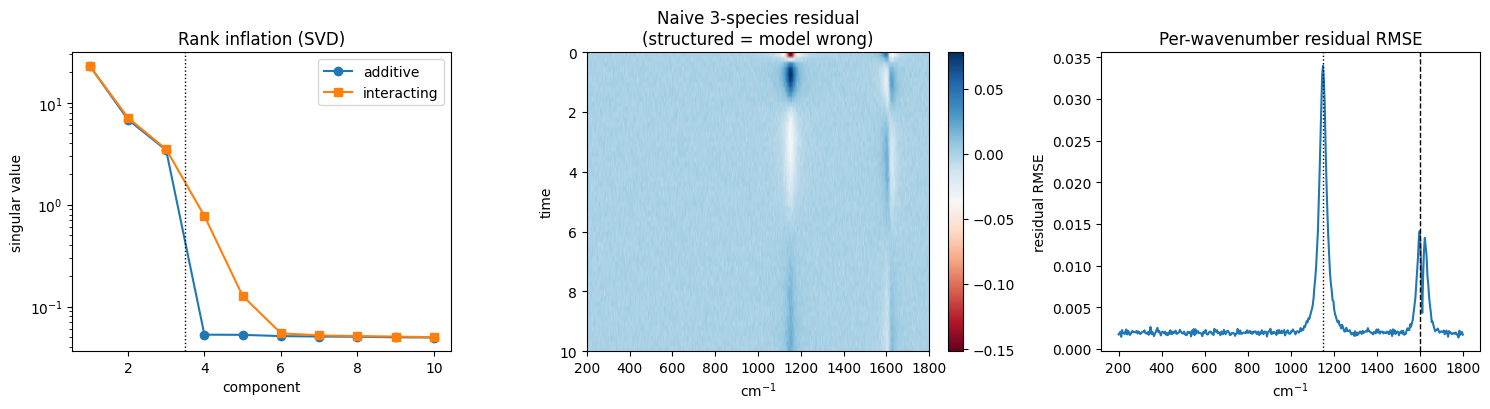

In [13]:
_optional_figure(sv_add, sv_int, R_int, col_rmse_int)
dict(sv_add=sv_add, sv_int=sv_int, R_add=R_add, R_int=R_int)